In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.datasets import load_iris

# Loading the dataset

In [20]:
iris = load_iris(as_frame=True)

df = iris.frame.copy()

df['species'] = df['target'].map(
    dict(enumerate(iris.target_names))
)

df = df.drop(columns="target")

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# Basic Data Inspection

In [21]:
df.shape

(150, 5)

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [23]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [24]:
df.isna().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [25]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

# Feature Distributions

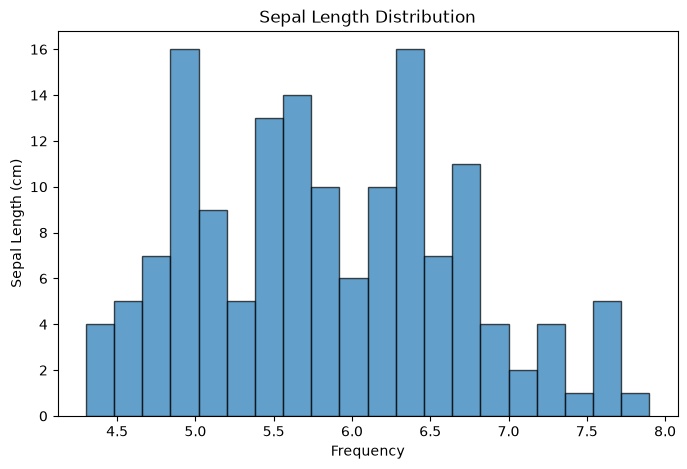

In [26]:
fig, ax = plt.subplots(figsize=(8,5))

ax.hist(
    df["sepal length (cm)"],
    bins=20,
    edgecolor="black",
    alpha=0.7
)

ax.set_title("Sepal Length Distribution")
ax.set_ylabel("Sepal Length (cm)")
ax.set_xlabel("Frequency")

plt.show()

## Multiples features

In [27]:
features = df.select_dtypes(include="number").columns
features

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='str')

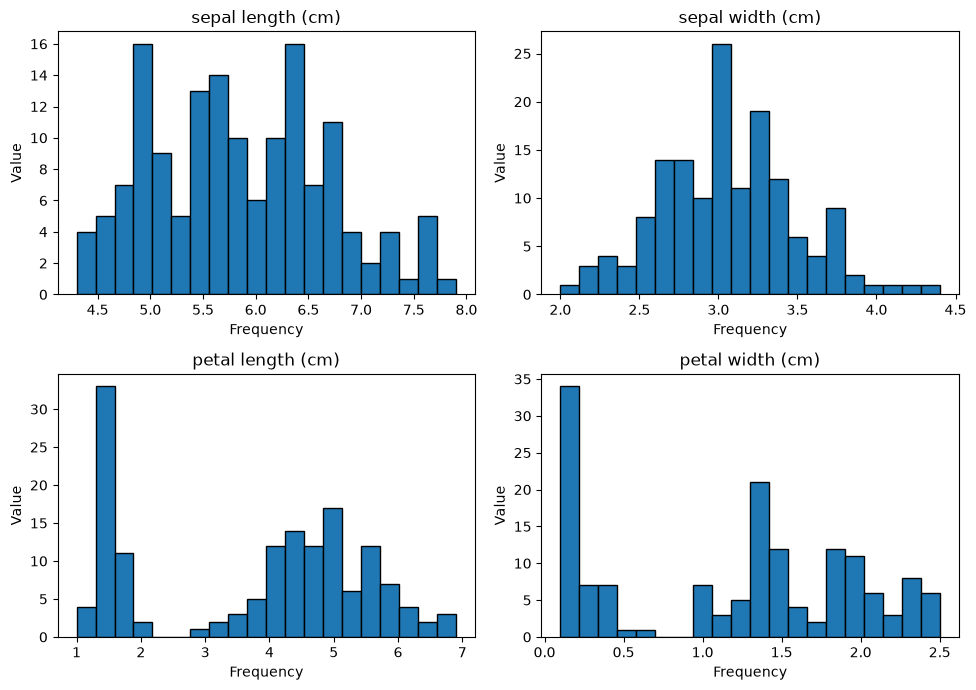

In [28]:
fig, axes = plt.subplots(2,2, figsize=(10,7))
for ax, feature in zip(axes.flat, features):
    ax.hist(df[feature], bins=20, edgecolor="black")
    ax.set_title(feature)
    ax.set_ylabel("Value")
    ax.set_xlabel("Frequency")

fig.tight_layout()
plt.show()

# Correlation Matrix
Permite ver que tan relacionadas están las variables numéricas

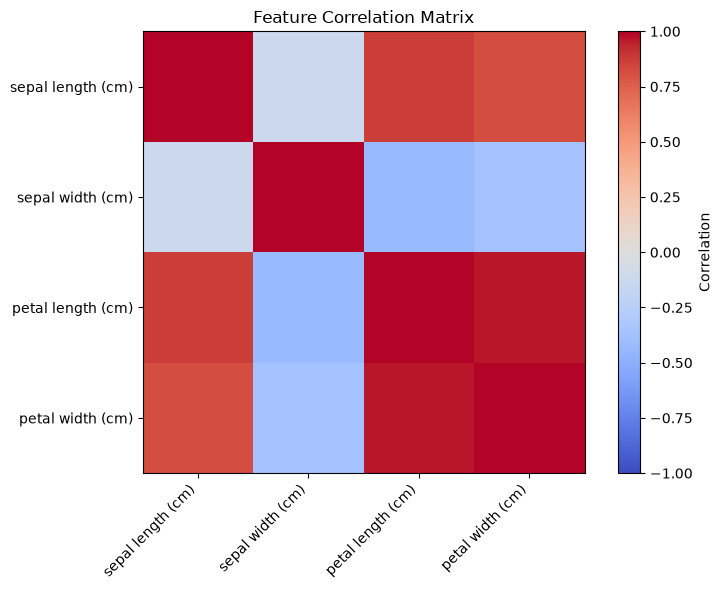

In [29]:
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features)), labels=features)
ax.set_yticks(range(len(features)), labels=features)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

fig.colorbar(im, ax=ax, label="Correlation")

ax.set_title("Feature Correlation Matrix")

fig.tight_layout()
plt.show()

# Feature Relationship - Scatter Plots

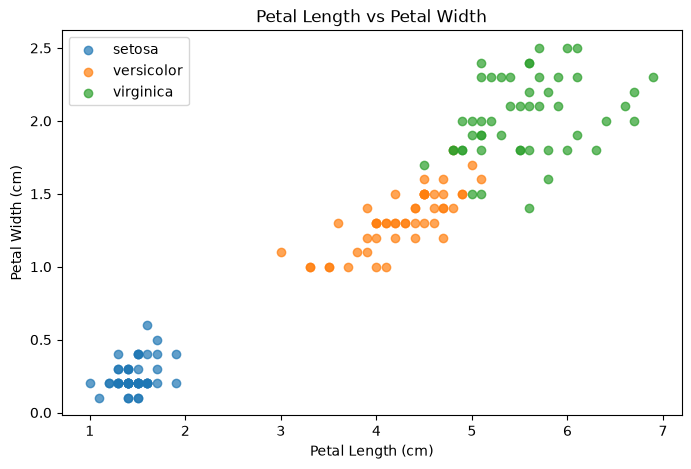

In [30]:
fig, ax = plt.subplots(figsize=(8,5))

for species, group in df.groupby("species"):
    ax.scatter(
        group["petal length (cm)"],
        group["petal width (cm)"],
        label=species,
        alpha=0.7
    )

ax.set_title("Petal Length vs Petal Width")
ax.set_xlabel("Petal Length (cm)")
ax.set_ylabel("Petal Width (cm)")

ax.legend()
plt.show()

# Class Distribution - Bar Chart
Cantidad de muestra por clase

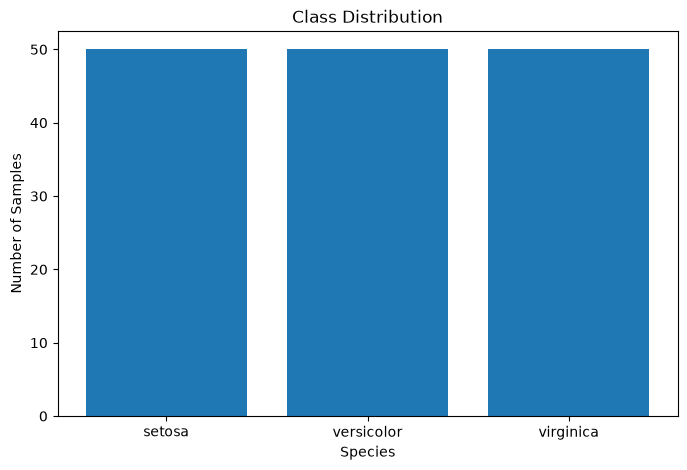

In [33]:
number = df["species"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(number.index, number.values)

ax.set_title("Class Distribution")
ax.set_xlabel("Species")
ax.set_ylabel("Number of Samples")

plt.show()

# Comparing Features by Class - Boxplots
Comparar como se distribuye una caracteristica entre diferentes clases

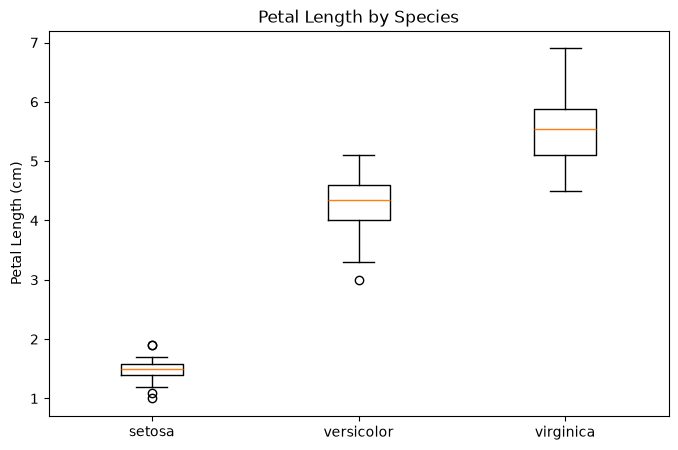

In [34]:
species = df["species"].unique()

data = [
    df.loc[
        df["species"] == name,
        "petal length (cm)"
    ]
    for name in species
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(data, tick_labels=species)

ax.set_title("Petal Length by Species")
ax.set_ylabel("Petal Length (cm)")

plt.show()

# Scatter Matrix - Multiple Feature Relationship
Cuando necesitamos estudiar lsa relaciones entre muchas caracteristicas, podemos crear una matriz de dispersión 

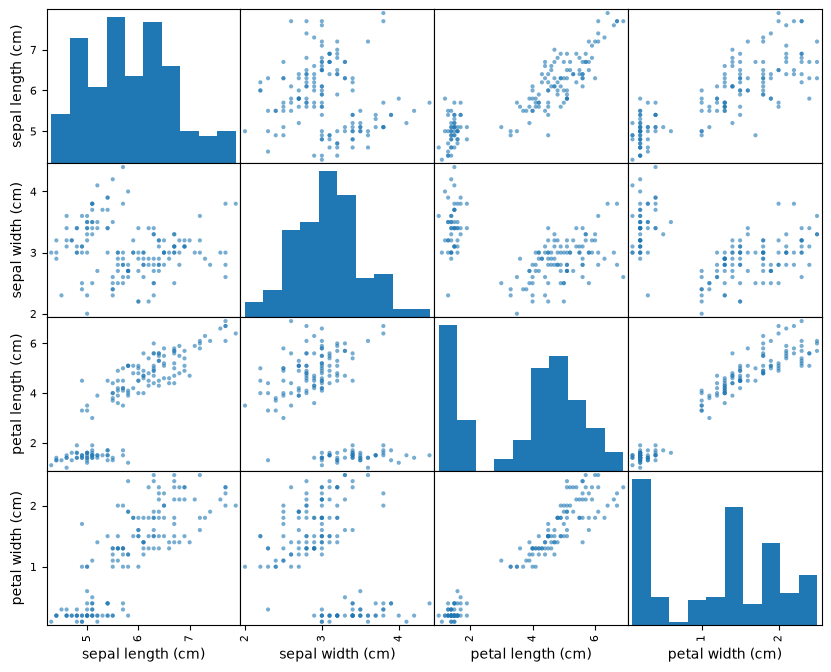

In [35]:
pd.plotting.scatter_matrix(
    df[features],
    figsize=(10,8),
    diagonal="hist",
    alpha=0.6
)

plt.show()

# Complete Example

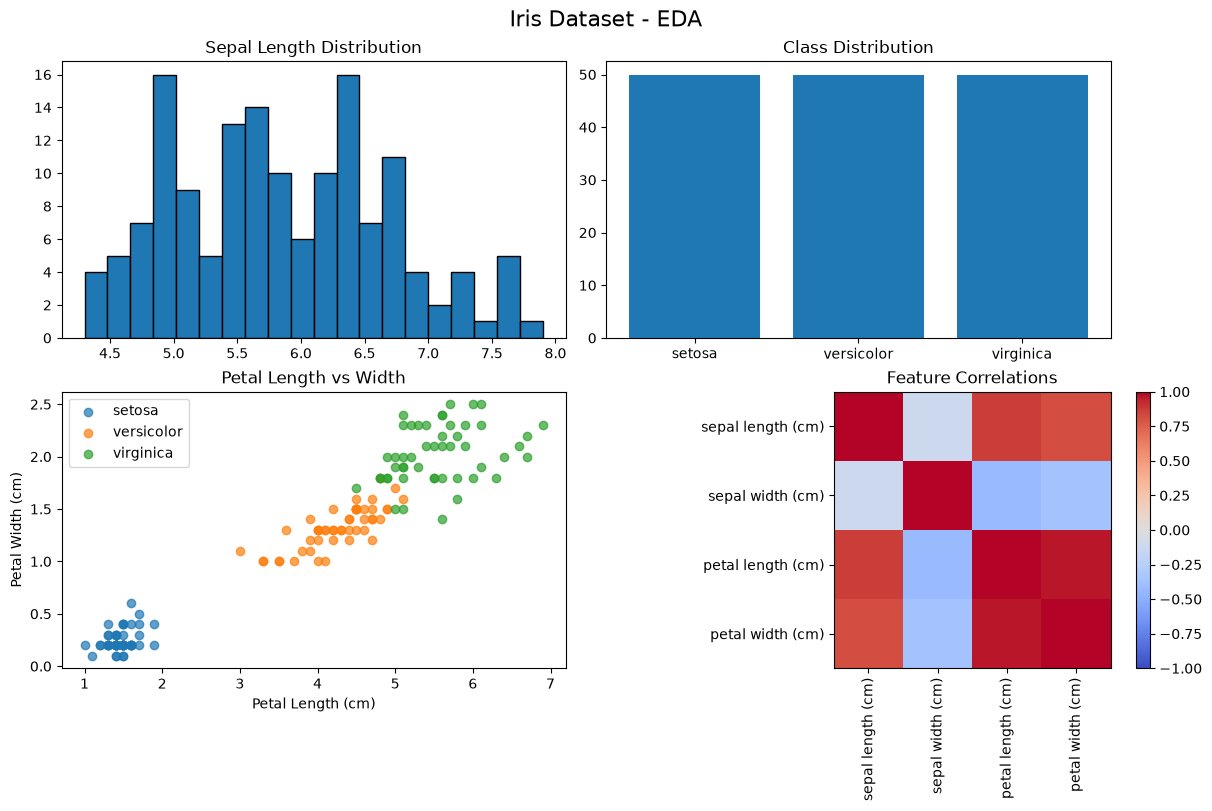

In [36]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    constrained_layout=True
)

# 1. Distribution
axes[0, 0].hist(
    df["sepal length (cm)"],
    bins=20,
    edgecolor="black"
)
axes[0, 0].set_title("Sepal Length Distribution")

# 2. Class distribution
counts = df["species"].value_counts()

axes[0, 1].bar(counts.index, counts.values)
axes[0, 1].set_title("Class Distribution")

# 3. Feature relationship
for species, group in df.groupby("species"):
    axes[1, 0].scatter(
        group["petal length (cm)"],
        group["petal width (cm)"],
        label=species,
        alpha=0.7
    )

axes[1, 0].set_title("Petal Length vs Width")
axes[1, 0].set_xlabel("Petal Length (cm)")
axes[1, 0].set_ylabel("Petal Width (cm)")
axes[1, 0].legend()

# 4. Correlation matrix
im = axes[1, 1].imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

axes[1, 1].set_xticks(
    range(len(features)),
    labels=features,
    rotation=90
)

axes[1, 1].set_yticks(
    range(len(features)),
    labels=features
)

axes[1, 1].set_title("Feature Correlations")

fig.colorbar(im, ax=axes[1, 1])

fig.suptitle("Iris Dataset - EDA", fontsize=16)

plt.show()